First five rows:
   fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0            7.4              0.70         0.00  ...       0.56      9.4        5
1            7.8              0.88         0.00  ...       0.68      9.8        5
2            7.8              0.76         0.04  ...       0.65      9.8        5
3           11.2              0.28         0.56  ...       0.58      9.8        6
4            7.4              0.70         0.00  ...       0.56      9.4        5

[5 rows x 12 columns]

Dataset shape:
(1599, 12)

 Column names:
Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')

Missing Values:
<bound method DataFrame.isnull of       fixed acidity  volatile acidity  citric acid  ...  sulphates  alcohol  quality
0               7.4             0.700         0.00  ...       0

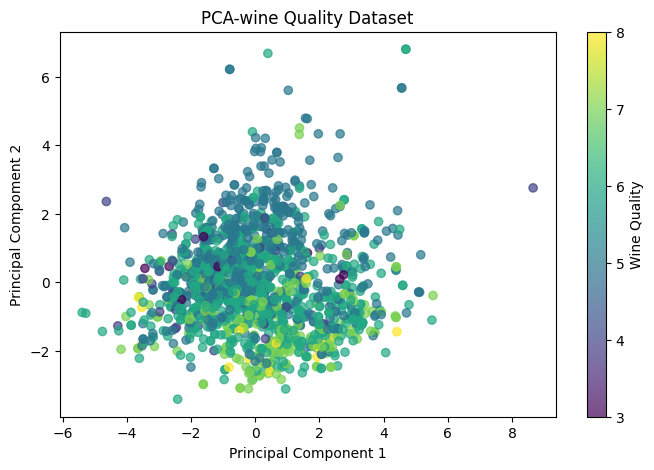

In [10]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

df = pd.read_csv("winequality-red.csv")
print("First five rows:")
print(df.head())

print("\nDataset shape:")
print(df.shape)

print("\n Column names:")
print(df.columns)

print("\nMissing Values:")
print(df.isnull)

X=df.drop("quality",axis=1)
Y=df["quality"]

normalizer = MinMaxScaler()
X_normalized = normalizer.fit_transform(X)

print("\nNormalized data(first 5 rows):")
print(pd.DataFrame(
    X_normalized, columns=X.columns).head().round(3))

standardizer= StandardScaler()
X_standardized = standardizer.fit_transform(X)

print("\nStandardized data(first 5 rows):")
print(pd.DataFrame(
    X_standardized, columns=X.columns
).head().round(3))

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_standardized)

print("\nPCA output(first 5 rows):")
print(pd.DataFrame(
    X_pca, columns=["PC1","PC2"]
).head().round(3))

print("\nOriginal number of features:",X.shape[1])
print("Reduced number of features:",X_pca.shape[1])

print("\nVariance retained by each component:")
print(pca.explained_variance_ratio_.round(4))

print("Total variance retained:",
      round(sum(pca.explained_variance_ratio_)* 100,2),"%")

plt.figure(figsize=(8,5))
plt.scatter(X_pca[:,0],X_pca[:,1],
            c=Y, cmap="viridis",alpha=0.7)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Compoment 2")
plt.title("PCA-wine Quality Dataset")
plt.colorbar(label="Wine Quality")
plt.show()